<a href="https://colab.research.google.com/github/newhoff88473099/fraud-detection/blob/main/deteccao_fraude_cartao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detecção de fraude em cartão de crédito

**Objetivo:** construir um classificador que identifica transações fraudulentas e explicar o que levou uma transação a ser marcada como fraude.

**Base:** transações de cartão de crédito de clientes europeus (set/2013, dois dias de dados).

**O ponto central é o desbalanceamento.** Cerca de 99,8% das transações são normais. Um modelo que responde "não é fraude" para tudo acerta quase sempre e não detecta nada. Por isso a **acurácia sai de cena** e o foco passa para **recall** (quantas fraudes o modelo pega), **precisão** (quantos alertas são de fato fraude) e **F1/F2** da classe de fraude, além de curvas de precisão e recall.

**Roteiro**
1. Explorar os dados
2. Preparar (variáveis novas, padronização, separação estratificada)
3. Treinar e comparar modelos (pesos de classe, limiar de decisão, undersampling e oversampling)
4. Avaliar (relatório de classificação, curvas ROC e de precisão × recall)
5. Explicar (importância das variáveis e SHAP)

## 1. Configuração

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score, fbeta_score,
                             average_precision_score, roc_auc_score, roc_curve, precision_recall_curve,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
import shap

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
os.makedirs("imagens", exist_ok=True)
os.makedirs("resultados", exist_ok=True)

def salvar(nome):
    """Salva a figura atual em imagens/ (as figuras do README vêm daqui)."""
    plt.savefig(f"imagens/{nome}.png", bbox_inches="tight", dpi=130)

print("Bibliotecas carregadas.")

Bibliotecas carregadas.


---
## 2. Explorar

A base é carregada **pelo link**, sem ficar no repositório. Se o link estiver indisponível, o código usa uma cópia local do arquivo `creditcard.csv` (ignorada pelo Git, via `.gitignore`); o caminho pode ser definido na variável de ambiente `CREDITCARD_CSV`.

In [2]:
URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
CAMINHO_LOCAL = os.environ.get("CREDITCARD_CSV", "creditcard.csv")

try:
    df = pd.read_csv(URL)
    origem = "link"
except Exception as erro:
    print(f"Link indisponível ({type(erro).__name__}). Usando o arquivo local: {CAMINHO_LOCAL}")
    df = pd.read_csv(CAMINHO_LOCAL)
    origem = "arquivo local"

print(f"Base carregada de: {origem}")
print(f"Linhas: {df.shape[0]:,} | Colunas: {df.shape[1]}")
df.head()

Base carregada de: link
Linhas: 284,807 | Colunas: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print("Tipos de dados:", df.dtypes.value_counts().to_dict())
print("Valores nulos no total:", int(df.isna().sum().sum()))
print("Linhas duplicadas:", int(df.duplicated().sum()))
df[["Time", "Amount", "Class"]].describe().T

Tipos de dados: {dtype('float64'): 30, dtype('int64'): 1}
Valores nulos no total: 0
Linhas duplicadas: 1081


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16
Class,284807.0,0.001727,0.041527,0.0,0.0,0.0,0.000,1.00


**Linhas duplicadas.** Linhas idênticas podem cair em treino e teste ao mesmo tempo e inflar a avaliação. Elas são removidas antes da separação.

In [4]:
antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removidas {antes - len(df):,} linhas duplicadas. Restam {len(df):,}.")

Removidas 1,081 linhas duplicadas. Restam 283,726.


### 2.1 Proporção de fraudes

,transações,%
normal (0),283253,99.8333
fraude (1),473,0.1667


Fraudes: 473 de 283,726 transações (0.167%).
Há cerca de 599 transações normais para cada fraude.


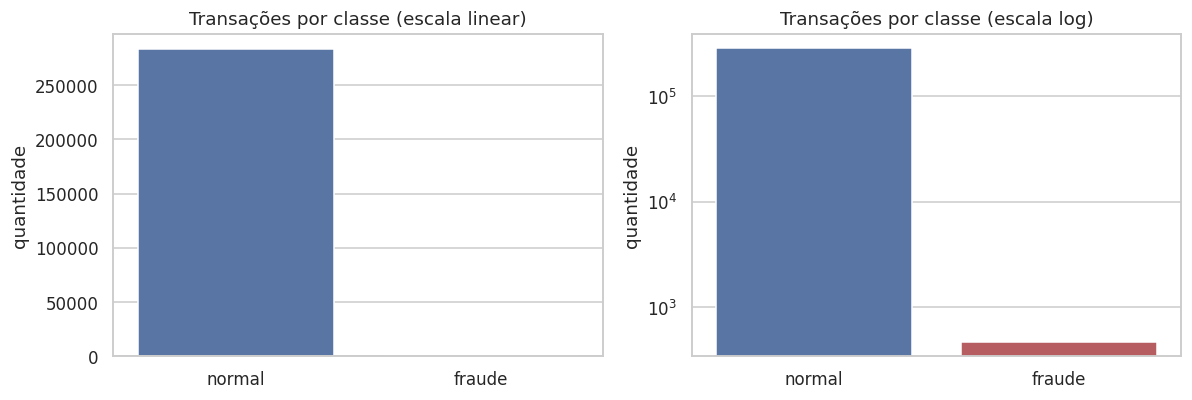

In [5]:
contagem = df["Class"].value_counts().sort_index()
proporcao = df["Class"].value_counts(normalize=True).sort_index() * 100

resumo = pd.DataFrame({"transações": contagem, "%": proporcao.round(4)})
resumo.index = ["normal (0)", "fraude (1)"]
display(resumo)

n_fraudes, n_normais = int(contagem[1]), int(contagem[0])
print(f"Fraudes: {n_fraudes} de {len(df):,} transações ({proporcao[1]:.3f}%).")
print(f"Há cerca de {n_normais / n_fraudes:.0f} transações normais para cada fraude.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.barplot(x=["normal", "fraude"], y=contagem.values, ax=ax[0], palette=["#4c72b0", "#c44e52"])
ax[0].set_title("Transações por classe (escala linear)"); ax[0].set_ylabel("quantidade")
sns.barplot(x=["normal", "fraude"], y=contagem.values, ax=ax[1], palette=["#4c72b0", "#c44e52"])
ax[1].set_yscale("log"); ax[1].set_title("Transações por classe (escala log)"); ax[1].set_ylabel("quantidade")
plt.tight_layout(); salvar("01_distribuicao_classes"); plt.show()

### 2.2 Por que a acurácia engana



In [6]:
dummy = DummyClassifier(strategy="most_frequent").fit(df[["Amount"]], df["Class"])
pred_dummy = dummy.predict(df[["Amount"]])
print(f"Acurácia do modelo que diz 'não é fraude' para tudo: {accuracy_score(df['Class'], pred_dummy):.4%}")
print(f"Recall da fraude: {recall_score(df['Class'], pred_dummy):.0%}   |   Fraudes detectadas: 0 de {n_fraudes}")

Acurácia do modelo que diz 'não é fraude' para tudo: 99.8333%
Recall da fraude: 0%   |   Fraudes detectadas: 0 de 473


A acurácia fica em torno de 99,8% e o modelo não detecta **nenhuma** fraude. Daqui em diante a métrica principal é o **recall da classe de fraude**, sempre olhado junto com a **precisão**, para que o modelo não "ganhe" recall marcando tudo como fraude.

### 2.3 Valor e horário das transações

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
normal,283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
fraude,473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87


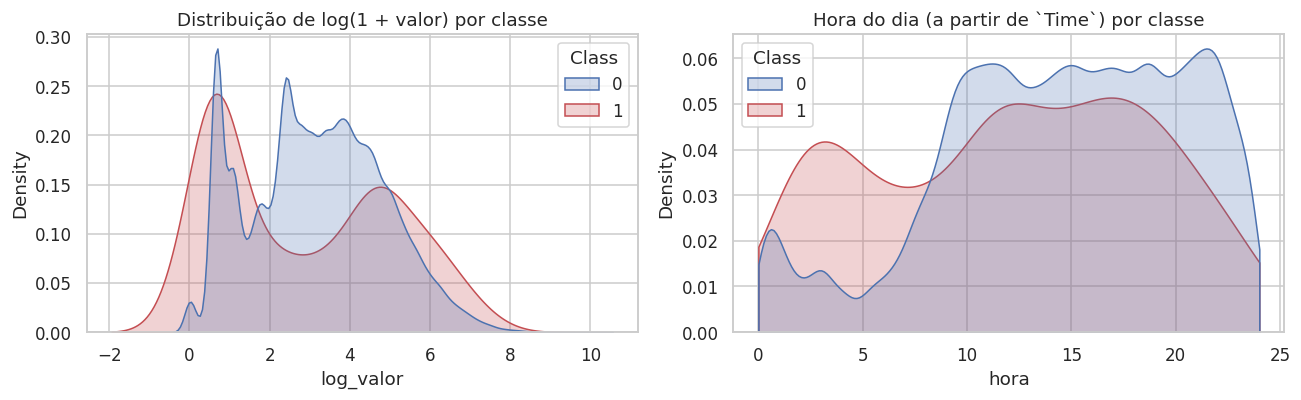

In [7]:
display(df.groupby("Class")["Amount"].describe().rename(index={0: "normal", 1: "fraude"}).round(2))

df_eda = df.assign(hora=(df["Time"] / 3600) % 24, log_valor=np.log1p(df["Amount"]))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.kdeplot(data=df_eda, x="log_valor", hue="Class", common_norm=False, fill=True, ax=ax[0],
            palette={0: "#4c72b0", 1: "#c44e52"})
ax[0].set_title("Distribuição de log(1 + valor) por classe")
sns.kdeplot(data=df_eda, x="hora", hue="Class", common_norm=False, fill=True, ax=ax[1],
            palette={0: "#4c72b0", 1: "#c44e52"}, clip=(0, 24))
ax[1].set_title("Hora do dia (a partir de `Time`) por classe")
plt.tight_layout(); salvar("02_valor_e_hora"); plt.show()

O valor tem cauda muito longa (poucas transações muito altas), o que justifica trabalhar com o **logaritmo do valor**. O horário mostra que as fraudes não seguem exatamente o mesmo ritmo das transações normais, então a **hora do dia** pode ajudar o modelo.

---
## 4. Preparar


In [8]:
df["log_valor"] = np.log1p(df["Amount"])
df["hora"] = (df["Time"] / 3600) % 24

colunas_v = [f"V{i}" for i in range(1, 29)]
variaveis = colunas_v + ["log_valor", "hora"]
X = df[variaveis]
y = df["Class"].values

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_treino, y_treino, test_size=0.25, stratify=y_treino, random_state=SEED)

tabela = pd.DataFrame({
    "conjunto": ["treino (fit)", "validação", "teste"],
    "transações": [len(y_fit), len(y_val), len(y_teste)],
    "fraudes": [int(y_fit.sum()), int(y_val.sum()), int(y_teste.sum())],
})
tabela["% de fraude"] = (tabela["fraudes"] / tabela["transações"] * 100).round(3)
tabela

,conjunto,transações,fraudes,% de fraude
0,treino (fit),170235,284,0.167
1,validação,56745,94,0.166
2,teste,56746,95,0.167


A proporção de fraudes é praticamente a mesma nos três conjuntos, como esperado com `stratify`.

**Peso das classes.** Em vez de alterar os dados, os modelos recebem um peso maior para a classe de fraude (`class_weight` no scikit-learn, `scale_pos_weight` no XGBoost).

In [9]:
peso_pos = (y_fit == 0).sum() / (y_fit == 1).sum()
print(f"scale_pos_weight = normais / fraudes (treino) = {peso_pos:.0f}")

scale_pos_weight = normais / fraudes (treino) = 598


---
## 5. Treinar

### 5.1 Funções de apoio

- `melhor_limiar`: o modelo devolve uma **probabilidade** de fraude; o limiar de decisão (padrão 0,5) transforma a probabilidade em "fraude / não fraude". Em dados desbalanceados, 0,5 quase nunca é o melhor ponto. O limiar é escolhido na **validação**, maximizando o **F2**, que dá peso maior ao recall do que à precisão (beta = 2). A escolha reflete o problema: deixar passar uma fraude custa mais do que investigar um alerta falso.
- `metricas`: recall, precisão, F1, F2 (classe de fraude), PR-AUC e ROC-AUC.

In [10]:
def melhor_limiar(y_real, proba, beta=2):
    """Limiar que maximiza o F-beta (beta=2 privilegia o recall) no conjunto informado."""
    prec, rec, lims = precision_recall_curve(y_real, proba)
    prec, rec = prec[:-1], rec[:-1]
    f = (1 + beta**2) * prec * rec / np.maximum(beta**2 * prec + rec, 1e-12)
    i = int(np.argmax(f))
    return float(lims[i]), float(f[i])

def metricas(y_real, proba, limiar):
    pred = (proba >= limiar).astype(int)
    return {
        "recall": recall_score(y_real, pred),
        "precisão": precision_score(y_real, pred, zero_division=0),
        "F1": f1_score(y_real, pred),
        "F2": fbeta_score(y_real, pred, beta=2),
        "PR-AUC": average_precision_score(y_real, proba),
        "ROC-AUC": roc_auc_score(y_real, proba),
        "limiar": limiar,
        "fraudes detectadas": int(((pred == 1) & (y_real == 1)).sum()),
        "alertas falsos": int(((pred == 1) & (y_real == 0)).sum()),
    }

resultados = {}   # guarda modelo, probabilidades e limiar escolhido

def registrar(nome, modelo):
    """Calcula probabilidades em validação e teste e escolhe o limiar na validação."""
    p_val = modelo.predict_proba(X_val)[:, 1]
    p_teste = modelo.predict_proba(X_teste)[:, 1]
    limiar, f2_val = melhor_limiar(y_val, p_val)
    resultados[nome] = {"modelo": modelo, "p_val": p_val, "p_teste": p_teste,
                        "limiar": limiar, "F2_val": f2_val,
                        "PR-AUC_val": average_precision_score(y_val, p_val)}

def treinar(nome, modelo):
    t0 = time.time()
    modelo.fit(X_fit, y_fit)
    registrar(nome, modelo)
    r = resultados[nome]
    print(f"{nome:<42} treino em {time.time()-t0:5.1f}s | limiar={r['limiar']:.3f} | "
          f"F2 val={r['F2_val']:.3f} | PR-AUC val={r['PR-AUC_val']:.3f}")

### 5.2 Baseline e comparação com pesos de classe

1. **Regressão logística** (baseline) com `class_weight="balanced"`.
2. **Random Forest** com `class_weight="balanced_subsample"`.
3. **XGBoost** com `scale_pos_weight`.

In [11]:
treinar("Regressão Logística (peso de classe)",
        Pipeline([("escala", StandardScaler()),
                  ("clf", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))]))

treinar("Random Forest (peso de classe)",
        RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=3,
                               class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))

treinar("XGBoost (peso de classe)",
        XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8,
                      colsample_bytree=0.8, scale_pos_weight=peso_pos, tree_method="hist",
                      eval_metric="aucpr", n_jobs=-1, random_state=SEED))

Regressão Logística (peso de classe)       treino em   1.2s | limiar=1.000 | F2 val=0.844 | PR-AUC val=0.790
Random Forest (peso de classe)             treino em 170.9s | limiar=0.459 | F2 val=0.864 | PR-AUC val=0.865
XGBoost (peso de classe)                   treino em  10.9s | limiar=0.479 | F2 val=0.871 | PR-AUC val=0.882


### 5.3 Alternativas: undersampling e oversampling

Em vez de pesar as classes, os dados de **treino** são reamostrados (a validação e o teste nunca são). A reamostragem fica dentro do `Pipeline` do `imblearn`, então só é aplicada ao ajustar o modelo.

- **Undersampling** (`RandomUnderSampler`): descarta normais até que as fraudes sejam 10% dos normais.
- **Oversampling** (`SMOTE`): cria fraudes sintéticas até chegar a 10% dos normais.

In [12]:
treinar("Regressão Logística + Undersampling",
        ImbPipeline([("amostra", RandomUnderSampler(sampling_strategy=0.1, random_state=SEED)),
                     ("escala", StandardScaler()),
                     ("clf", LogisticRegression(max_iter=2000, random_state=SEED))]))

treinar("Regressão Logística + SMOTE",
        ImbPipeline([("amostra", SMOTE(sampling_strategy=0.1, random_state=SEED)),
                     ("escala", StandardScaler()),
                     ("clf", LogisticRegression(max_iter=2000, random_state=SEED))]))

treinar("XGBoost + Undersampling",
        ImbPipeline([("amostra", RandomUnderSampler(sampling_strategy=0.1, random_state=SEED)),
                     ("clf", XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8,
                                           colsample_bytree=0.8, tree_method="hist", eval_metric="aucpr",
                                           n_jobs=-1, random_state=SEED))]))

Regressão Logística + Undersampling        treino em   0.2s | limiar=0.951 | F2 val=0.768 | PR-AUC val=0.759
Regressão Logística + SMOTE                treino em   1.6s | limiar=0.959 | F2 val=0.832 | PR-AUC val=0.800
XGBoost + Undersampling                    treino em   1.1s | limiar=0.989 | F2 val=0.862 | PR-AUC val=0.878


### 5.4 Ajuste de hiperparâmetros (GridSearchCV)

Busca em grade para o XGBoost com peso de classe, validação cruzada estratificada de 3 dobras no conjunto de treino (`X_fit`) e **PR-AUC** (`average_precision`) como métrica, mais adequada que a ROC-AUC para classes raras.

In [ ]:
grade = {"max_depth": [3, 5, 7],
         "learning_rate": [0.05, 0.1],
         "n_estimators": [200, 400]}

busca = GridSearchCV(
    XGBClassifier(subsample=0.8, colsample_bytree=0.8, scale_pos_weight=peso_pos, tree_method="hist",
                  eval_metric="aucpr", n_jobs=-1, random_state=SEED),
    param_grid=grade, scoring="average_precision",
    cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=1, refit=True)

t0 = time.time()
busca.fit(X_fit, y_fit)
print(f"Busca concluída em {time.time()-t0:.0f}s")
print("Melhores hiperparâmetros:", busca.best_params_)
print(f"PR-AUC média na validação cruzada: {busca.best_score_:.4f}")

registrar("XGBoost ajustado (GridSearchCV)", busca.best_estimator_)
r = resultados["XGBoost ajustado (GridSearchCV)"]
print(f"limiar={r['limiar']:.3f} | F2 val={r['F2_val']:.3f} | PR-AUC val={r['PR-AUC_val']:.3f}")

pd.DataFrame(busca.cv_results_)[["param_max_depth", "param_learning_rate", "param_n_estimators", "mean_test_score"]] \
    .sort_values("mean_test_score", ascending=False).round(4).reset_index(drop=True)

---
## 6. Avaliar

### 6.1 Comparação dos modelos

Duas leituras para cada modelo, ambas no **conjunto de teste** e sempre sobre a **classe de fraude**:

- **Limiar 0,5** (o padrão): mostra o que acontece sem ajuste.
- **Limiar ajustado** na validação (máximo F2).

A escolha do melhor modelo usa o **F2 da validação**, não o teste, para que o teste continue sendo uma medida honesta.

In [ ]:
def tabela_comparativa(usar_limiar_ajustado):
    linhas = []
    for nome, r in resultados.items():
        lim = r["limiar"] if usar_limiar_ajustado else 0.5
        m = metricas(y_teste, r["p_teste"], lim)
        linhas.append({"modelo": nome, **m})
    return pd.DataFrame(linhas).set_index("modelo")

cols = ["recall", "precisão", "F1", "F2", "PR-AUC", "ROC-AUC", "fraudes detectadas", "alertas falsos"]
print(f"Teste: {len(y_teste):,} transações, {int(y_teste.sum())} fraudes.\n")

print("Limiar padrão (0,5):")
tab_05 = tabela_comparativa(False)
display(tab_05[cols].round(4))

print("Limiar ajustado na validação (máx. F2):")
tab_aj = tabela_comparativa(True)
display(tab_aj[["limiar"] + cols].round(4))

tab_aj[["limiar"] + cols].round(4).to_csv("resultados/comparacao_modelos.csv")

In [ ]:
melhor_nome = max(resultados, key=lambda n: resultados[n]["F2_val"])
melhor = resultados[melhor_nome]
print(f"Melhor modelo pelo F2 na validação: {melhor_nome}")
print(f"Limiar de decisão escolhido: {melhor['limiar']:.4f}")

### 6.2 Curvas ROC e de precisão × recall

A curva ROC tende a parecer ótima em bases desbalanceadas, porque a taxa de falsos positivos é dividida por um número enorme de normais. A curva de **precisão × recall** é mais exigente e mais informativa aqui. A linha tracejada da PR é a precisão de um classificador aleatório (a prevalência de fraude).

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
for nome, r in resultados.items():
    fpr, tpr, _ = roc_curve(y_teste, r["p_teste"])
    ax[0].plot(fpr, tpr, label=f"{nome} (AUC {roc_auc_score(y_teste, r['p_teste']):.3f})")
    pr, rc, _ = precision_recall_curve(y_teste, r["p_teste"])
    ax[1].plot(rc, pr, label=f"{nome} (AP {average_precision_score(y_teste, r['p_teste']):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set(title="Curva ROC (teste)", xlabel="taxa de falsos positivos", ylabel="recall (taxa de verdadeiros positivos)")
ax[0].legend(fontsize=7.5, loc="lower right")
ax[1].axhline(y_teste.mean(), color="k", ls="--", lw=1, label=f"aleatório ({y_teste.mean():.4f})")
ax[1].set(title="Curva de precisão × recall (teste)", xlabel="recall", ylabel="precisão", ylim=(0, 1.02))
ax[1].legend(fontsize=7.5, loc="lower left")
plt.tight_layout(); salvar("03_curvas_roc_pr"); plt.show()

### 6.3 O limiar de decisão do melhor modelo

Na validação, recall e precisão se movem em sentidos opostos conforme o limiar. O ponto escolhido (máximo F2) está marcado.

In [ ]:
prec, rec, lims = precision_recall_curve(y_val, melhor["p_val"])
f2_curva = 5 * prec[:-1] * rec[:-1] / np.maximum(4 * prec[:-1] + rec[:-1], 1e-12)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(lims, prec[:-1], label="precisão")
ax.plot(lims, rec[:-1], label="recall")
ax.plot(lims, f2_curva, label="F2", color="gray", ls=":")
ax.axvline(melhor["limiar"], color="#c44e52", ls="--", label=f"limiar escolhido = {melhor['limiar']:.3f}")
ax.set(title=f"Limiar de decisão na validação: {melhor_nome}", xlabel="limiar", ylabel="valor")
ax.legend(); plt.tight_layout(); salvar("04_limiar"); plt.show()

### 6.4 Relatório de classificação e matriz de confusão (teste)

In [ ]:
pred_final = (melhor["p_teste"] >= melhor["limiar"]).astype(int)
print(f"Modelo: {melhor_nome} | limiar = {melhor['limiar']:.4f}\n")
print(classification_report(y_teste, pred_final, target_names=["normal", "fraude"], digits=4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ConfusionMatrixDisplay(confusion_matrix(y_teste, pred_final), display_labels=["normal", "fraude"]).plot(
    ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ax[0].set_title("Matriz de confusão (teste)")
ConfusionMatrixDisplay(confusion_matrix(y_teste, pred_final, normalize="true"), display_labels=["normal", "fraude"]).plot(
    ax=ax[1], cmap="Blues", colorbar=False, values_format=".3f")
ax[1].set_title("Normalizada por classe real")
plt.tight_layout(); salvar("05_matriz_confusao"); plt.show()

### 6.5 Comparação com o limiar padrão no melhor modelo

Quanto o ajuste do limiar muda o resultado, mantendo o mesmo modelo:

In [ ]:
comp = pd.DataFrame({"limiar 0,5": metricas(y_teste, melhor["p_teste"], 0.5),
                     f"limiar ajustado ({melhor['limiar']:.3f})": metricas(y_teste, melhor["p_teste"], melhor["limiar"])}).T
comp[["recall", "precisão", "F1", "F2", "fraudes detectadas", "alertas falsos"]].round(4)

---
## 7. Explicar

### 7.1 Importância das variáveis

Duas formas complementares, no modelo de árvores de melhor desempenho:

Como a análise é de modelos de árvore, o modelo explicado é o melhor deles pelo F2 na validação.

In [ ]:
def extrair_xgb(modelo):
    return modelo.named_steps["clf"] if hasattr(modelo, "named_steps") else modelo

candidatos_xgb = [n for n in resultados if "XGBoost" in n]
nome_explicado = max(candidatos_xgb, key=lambda n: resultados[n]["F2_val"])
rx = resultados[nome_explicado]
xgb_final = extrair_xgb(rx["modelo"])
lim_final = rx["limiar"]
print(f"Modelo explicado: {nome_explicado} | limiar = {lim_final:.4f}")

ganho = pd.Series(xgb_final.get_booster().get_score(importance_type="total_gain")).reindex(variaveis).fillna(0)
ganho = (ganho / ganho.sum()).sort_values(ascending=False)

perm = permutation_importance(rx["modelo"], X_teste, y_teste, scoring="average_precision",
                              n_repeats=5, random_state=SEED, n_jobs=1)
perm_s = pd.Series(perm.importances_mean, index=variaveis).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
ganho.head(15)[::-1].plot.barh(ax=ax[0], color="#4c72b0")
ax[0].set(title="Importância por ganho (top 15)", xlabel="fração do ganho total")
perm_s.head(15)[::-1].plot.barh(ax=ax[1], color="#55a868")
ax[1].set(title="Importância por permutação (top 15)", xlabel="queda média da PR-AUC no teste")
plt.tight_layout(); salvar("06_importancia_variaveis"); plt.show()

### 7.2 SHAP: o que pesou em cada decisão

O SHAP atribui a cada variável uma contribuição para a previsão de cada transação, partindo de um valor base (o comportamento médio do modelo). Aqui as contribuições estão em **log-odds** da classe de fraude: valores positivos empurram a transação para "fraude", negativos para "normal".

Para o gráfico global, a amostra tem **todas as fraudes do teste** e 2.000 transações normais sorteadas.

In [ ]:
rng = np.random.RandomState(SEED)
idx_fraude = np.where(y_teste == 1)[0]
idx_normal = rng.choice(np.where(y_teste == 0)[0], size=2000, replace=False)
idx_amostra = np.concatenate([idx_fraude, idx_normal])
X_amostra = X_teste.iloc[idx_amostra]

explicador = shap.TreeExplainer(xgb_final)
sv = explicador(X_amostra)
print("Valor base (log-odds):", round(float(np.ravel(sv.base_values)[0]), 3))

plt.figure()
shap.summary_plot(sv.values, X_amostra, show=False, max_display=15)
plt.title("SHAP: impacto de cada variável (fraudes + amostra de normais)")
plt.tight_layout(); salvar("07_shap_resumo"); plt.show()

In [ ]:
plt.figure()
shap.plots.bar(sv, max_display=15, show=False)
plt.title("SHAP: impacto médio absoluto")
plt.tight_layout(); plt.show()

### 7.3 Explicando transações individuais

Três casos do conjunto de teste, escolhidos pelo resultado:
- **Fraude detectada** (verdadeiro positivo): a de maior probabilidade.
- **Fraude não detectada** (falso negativo): a de menor probabilidade.
- **Alerta falso** (falso positivo): a normal com maior probabilidade de fraude.

In [ ]:
p_x = xgb_final.predict_proba(X_teste)[:, 1]
marcada = p_x >= lim_final

casos = {}
tp = np.where((y_teste == 1) & marcada)[0]
fn = np.where((y_teste == 1) & ~marcada)[0]
fp = np.where((y_teste == 0) & marcada)[0]
if len(tp): casos["fraude detectada"] = tp[np.argmax(p_x[tp])]
if len(fn): casos["fraude não detectada"] = fn[np.argmin(p_x[fn])]
if len(fp): casos["alerta falso"] = fp[np.argmax(p_x[fp])]

def explicar_transacao(pos, titulo, top=6):
    linha = X_teste.iloc[[pos]]
    s = explicador(linha)[0]
    ordem = np.argsort(-np.abs(s.values))[:top]
    print(f"== {titulo} | classe real: {'fraude' if y_teste[pos] else 'normal'} | "
          f"prob. de fraude: {p_x[pos]:.4f} | limiar: {lim_final:.3f} -> "
          f"{'MARCADA como fraude' if marcada[pos] else 'não marcada'}")
    for j in ordem:
        sentido = "empurra para FRAUDE " if s.values[j] > 0 else "empurra para NORMAL"
        print(f"   {s.feature_names[j]:<10} = {linha.iloc[0, j]:>9.3f}  {sentido} ({s.values[j]:+.2f})")
    print()
    return s

explicacoes = {t: explicar_transacao(pos, t) for t, pos in casos.items()}

In [ ]:
for i, (titulo, s) in enumerate(explicacoes.items()):
    plt.figure()
    shap.plots.waterfall(s, max_display=10, show=False)
    plt.title(titulo)
    plt.tight_layout()
    salvar(f"08_shap_{['fraude_detectada','fraude_nao_detectada','alerta_falso'][i] if len(explicacoes)==3 else i}")
    plt.show()

---
## 8. Conclusões

**O que os números dizem (conjunto de teste: 56.746 transações, 95 fraudes)**

- **Acurácia não serve aqui.** O modelo que responde "não é fraude" para tudo tem 99,83% de acurácia e recall zero. O melhor modelo tem 99,95%, mas o que importa é que ele detecta **74 das 95 fraudes (recall 77,9%)** com **precisão de 92,5%** (6 alertas falsos em 56.651 transações normais).
- **Modelo escolhido: XGBoost ajustado (GridSearchCV)**, pelo maior F2 na validação, com limiar de decisão 0,32. No teste: recall 0,779, precisão 0,925, F1 0,846, PR-AUC 0,820.
- **Modelos de árvore vencem a regressão logística.** Com peso de classe e limiar ajustado, a regressão logística chega a recall 0,768, mas com precisão 0,777 (21 alertas falsos) e PR-AUC 0,680, contra 0,820 do XGBoost.
- **O limiar importa muito para a regressão logística, pouco para as árvores.** No limiar 0,5 a regressão logística marca 1.596 alertas falsos (precisão 0,049); com limiar 0,9998 a precisão sobe para 0,777. Já no XGBoost, mover o limiar de 0,5 para 0,32 manteve o recall (74 fraudes) e custou 2 alertas falsos a mais: os escores das árvores já são bem separados.
- **Undersampling e SMOTE não superaram o peso de classe.** No limiar 0,5 eles dão mais recall (até 0,83 no XGBoost + undersampling), mas à custa de 99 a 171 alertas falsos. Com o limiar ajustado, o XGBoost com peso de classe teve F2 0,813 contra 0,752 do XGBoost com undersampling.
- **Cuidado com a leitura das diferenças.** O teste tem só 95 fraudes: uma fraude a mais ou a menos muda o recall em cerca de 1 ponto percentual. O XGBoost com peso de classe (sem ajuste de hiperparâmetros) fica a 1 fraude do modelo escolhido (75 contra 74) e tem F2 de teste ligeiramente maior (0,813 contra 0,804). A escolha foi feita na validação, que também é pequena (94 fraudes); as diferenças entre os dois XGBoost estão dentro do ruído.

**O que o SHAP mostrou**

- As variáveis que mais pesam são **V14, V4, V12 e V10**. Valores **baixos de V14, V12 e V10** e valores **altos de V4** empurram a transação para fraude. Como são componentes da PCA, não dá para dar nome de negócio a elas; dá para dizer que a assinatura da fraude está nessas direções.
- A **hora do dia** aparece entre as 10 mais importantes no SHAP; o valor (`log_valor`) pesa pouco no geral, mas contribuiu em transações específicas.
- No caso individual de **fraude detectada**, V14 (-13,7) sozinha somou +4,8 log-odds, seguida de V12, V4 e V10.
- Na **fraude não detectada**, V4, V14 e V11 tinham valores comuns de transações normais e puxaram a previsão para "normal". Esse é o limite do modelo: fraudes que se parecem com transações legítimas nas componentes disponíveis não são separadas.
- No **alerta falso**, V14 (-7,1), V10 e V12 apontaram para fraude, mesmo a transação sendo normal.
- A importância por permutação (queda da PR-AUC no teste) destaca V4, V14, V28, V11 e V1, uma ordem diferente da do SHAP. As duas medidas respondem a perguntas diferentes (contribuição média para a previsão contra perda ao embaralhar a variável), e V4 e V14 aparecem bem nas duas.

**Limitações e próximos passos**

- Resultados vêm de **uma única separação treino/validação/teste**. Validação cruzada repetida daria um intervalo de confiança para o recall.
- O limiar foi escolhido pelo F2 (recall com peso 2). Em um uso real o limiar deve vir do **custo de uma fraude não detectada contra o custo de investigar um alerta**.
- Ideias: ampliar a grade de hiperparâmetros, testar outros modelos (LightGBM, rede neural pequena), criar variáveis de comportamento ao longo do tempo (transações em sequência, o que exigiria identificar o cartão, informação que a base anonimizada não traz) e calibrar as probabilidades.

In [ ]:
r = tab_aj.loc[melhor_nome]
print(f"Modelo escolhido (F2 na validação): {melhor_nome}")
print(f"Limiar de decisão: {r['limiar']:.4f}")
print(f"No teste: recall = {r['recall']:.3f} | precisão = {r['precisão']:.3f} | F1 = {r['F1']:.3f} | "
      f"PR-AUC = {r['PR-AUC']:.3f}")
print(f"Fraudes detectadas: {int(r['fraudes detectadas'])} de {int(y_teste.sum())} | alertas falsos: {int(r['alertas falsos'])} "
      f"em {int((y_teste == 0).sum()):,} transações normais")
print("Variáveis mais importantes (permutação):", ", ".join(perm_s.head(5).index))